## Goal: Train a quantum machine learning model to rank promising portfolios of 6 stocks selected from 12, and evaluate its recommendations against classical baselines and the exact optimum.

# Intermediate Level: Quantum Machine Learning for Portfolio Evaluation

## 1. Project Overview

This notebook explores Quantum Machine Learning (QML) for classifying and evaluating candidate investment portfolios. It combines a classical portfolio-generation pipeline, a quantum feature map, a quantum fidelity kernel, and Support Vector Machine (SVM) classification.

The objective is to investigate whether quantum-derived similarity measures can help distinguish promising portfolios from less promising ones and how the resulting portfolio rankings compare with classical approaches.

This experiment complements the Advanced notebook, which uses QAOA to solve a constrained optimization problem directly. Here, the focus is on quantum feature representation, kernel-based learning, and portfolio ranking rather than QAOA.

## 2. Portfolio Problem and Dataset

The experiment uses a synthetic universe of 12 stocks and considers portfolios containing exactly 6 stocks.

The number of candidate portfolios is

\[
\binom{12}{6}=\frac{12!}{6!\,6!}=924.
\]

Each portfolio is represented by a 12-dimensional binary vector. An entry of 1 indicates that a stock is selected, while 0 indicates that it is excluded.

The notebook generates the portfolio features and associated risk-return information, including a covariance matrix of shape \(12\times12\). The risk-aversion parameter is \(q=0.5\), and the penalty parameter used in the portfolio formulation is 1.0.

An exact classical search establishes the reference portfolio:

- Selected stocks: Stock 2, Stock 6, Stock 7, Stock 9, Stock 11, and Stock 12.
- Reference objective cost: approximately −1.066392.

The reference optimum provides a ground truth for evaluating portfolio rankings. Because the data are synthetic and the candidate space is relatively small, the experiment is a controlled methodological demonstration rather than a real-world investment recommendation.

## 3. Learning Task

Candidate portfolios are assigned labels based on their objective costs. The notebook focuses on distinguishing particularly good portfolios from particularly poor portfolios.

The recorded thresholds are:

- Good-portfolio threshold: −0.747000.
- Poor-portfolio threshold: −0.540194.

Portfolios in the intermediate range are excluded from the binary classification examples. This creates a more clearly separated classification task while reducing the number of available examples.

The dataset preparation recorded 693 candidates in the training pool and 231 in the held-out candidate pool. The labeled training set contains 348 examples: 174 good and 174 poor portfolios. The notebook's held-out classification evaluation uses the labeled examples available after filtering.

The distinction between the full candidate pool and the labeled subset is important: not every candidate portfolio is necessarily used to train or evaluate the classifier.

## 4. Quantum Feature Map and Fidelity Kernel

A quantum feature map transforms a classical input vector into a quantum state:

\[
x\longmapsto |\phi(x)\rangle.
\]

The quantum fidelity kernel compares two encoded states using

\[
K(x_i,x_j)=
|\langle\phi(x_i)|\phi(x_j)\rangle|^2.
\]

The resulting kernel matrix represents similarities between portfolio inputs. It can then be supplied to a kernel-based learning algorithm such as an SVM.

This notebook uses a 12-qubit feature map with two repetitions. Its statevector representation has dimension

\[
2^{12}=4096.
\]

The feature-map checks verify that the generated quantum states are normalized and that the computed fidelity values satisfy basic kernel consistency checks, including a diagonal of ones.

The kernel is used as a similarity representation for the learning task. Constructing a quantum feature map does not, by itself, establish that the model performs better than a classical machine-learning method.

## 5. Models and Evaluation Strategy

The experiment compares a quantum-kernel SVM with a classical SVM using an RBF kernel. Both models are evaluated on labeled portfolio examples, and their predictions and portfolio-ranking behavior are compared against the classical reference.

The notebook records 100% classification accuracy for both methods on the initial evaluated split. This result should be interpreted in context: the dataset is synthetic, the classification task uses selected extreme examples, and the result on a single split does not establish generalization to unseen real-world investment data.

The notebook also performs repeated ranking evaluations. These are useful because a model may classify selected examples correctly without necessarily ranking all candidate portfolios in the same order as the classical objective.

Repeated evaluations therefore provide additional evidence about ranking stability and the consistency of the results.

## 6. Reproducibility and Scope

The notebook separates portfolio generation, label construction, quantum feature-map validation, kernel computation, model evaluation, and portfolio-ranking analysis.

The reference objective is calculated classically, allowing the learned rankings to be compared with a known benchmark.

The main limitations are the use of synthetic data, the exclusion of intermediate-cost portfolios from classification, the finite number of candidate portfolios, and the need to distinguish classification accuracy from optimization quality.

The purpose is to study quantum-kernel machine learning in a controlled environment. No quantum advantage is claimed.

In [ ]:
# Intermediate QML — Step 1
# Generate the official 12-stock problem and classical reference

import numpy as np
from itertools import combinations

# Official challenge parameters
rng = np.random.default_rng(2026)

n, K, q = 12, 6, 0.5
lam = 1.0

# Generate the same data format used in the official challenge
mu = rng.uniform(0.05, 0.25, n)
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T

# Portfolio objective
def portfolio_cost(x, lam=1.0):
    x = np.asarray(x, dtype=int)

    expected_return = mu @ x
    risk = x @ sigma @ x
    penalty = lam * (x.sum() - K) ** 2

    return float(q * risk - expected_return + penalty)


# Generate all portfolios that select exactly six stocks
combinations_list = list(combinations(range(n), K))

X = np.zeros((len(combinations_list), n), dtype=np.int8)

for row, chosen in enumerate(combinations_list):
    X[row, list(chosen)] = 1


# Compute portfolio returns, risks, and objective values
X_float = X.astype(float)

portfolio_returns = X_float @ mu

portfolio_risks = np.einsum(
    "bi,ij,bj->b",
    X_float,
    sigma,
    X_float
)

portfolio_costs = (
    q * portfolio_risks
    - portfolio_returns
    + lam * (X.sum(axis=1) - K) ** 2
)


# Exact classical optimum over all valid portfolios
best_index = int(np.argmin(portfolio_costs))
best_x = X[best_index].copy()
best_cost = float(portfolio_costs[best_index])


# Validate the dataset
assert X.shape == (924, 12)
assert np.all(X.sum(axis=1) == K)
assert np.allclose(sigma, sigma.T)
assert np.allclose(portfolio_costs[best_index],
                   portfolio_cost(best_x, lam))


# Display the results

print("INTERMEDIATE QML — DATASET VALIDATION")


print(f"Number of stocks: {n}")
print(f"Stocks to select: {K}")
print(f"Risk-aversion parameter q: {q}")
print(f"Penalty strength lambda: {lam}")

print(f"\nCandidate portfolios: {X.shape[0]}")
print(f"Feature matrix shape: {X.shape}")
print(f"Covariance matrix shape: {sigma.shape}")

print("\nStock expected returns:")
for i, value in enumerate(mu):
    print(f"Stock {i + 1:02d}: {value:.5f}")

selected_stocks = [
    f"Stock {i + 1}"
    for i, selected in enumerate(best_x)
    if selected
]

print("\nExact classical reference:")
print("Selected stocks:", selected_stocks)
print(f"Expected return score: {mu @ best_x:.6f}")
print(f"Portfolio risk: {best_x @ sigma @ best_x:.6f}")
print(f"Minimum valid portfolio cost: {best_cost:.6f}")

print("\nAll dataset validation checks passed.")

INTERMEDIATE QML — DATASET VALIDATION
Number of stocks: 12
Stocks to select: 6
Risk-aversion parameter q: 0.5
Penalty strength lambda: 1.0

Candidate portfolios: 924
Feature matrix shape: (924, 12)
Covariance matrix shape: (12, 12)

Stock expected returns:
Stock 01: 0.08579
Stock 02: 0.17798
Stock 03: 0.14345
Stock 04: 0.12410
Stock 05: 0.12098
Stock 06: 0.20810
Stock 07: 0.23103
Stock 08: 0.08547
Stock 09: 0.18056
Stock 10: 0.10966
Stock 11: 0.24339
Stock 12: 0.23397

Exact classical reference:
Selected stocks: ['Stock 2', 'Stock 6', 'Stock 7', 'Stock 9', 'Stock 11', 'Stock 12']
Expected return score: 1.275034
Portfolio risk: 0.417285
Minimum valid portfolio cost: -1.066392

All dataset validation checks passed.


In [ ]:
# Intermediate QML — Step 2
# Prepare labeled portfolios and a held-out test set

import numpy as np
from sklearn.model_selection import train_test_split

# X and portfolio_costs come from Step 1
all_indices = np.arange(len(X))

# 75% of candidates for training; 25% held out for testing
train_pool_idx, test_pool_idx = train_test_split(
    all_indices,
    test_size=0.25,
    random_state=2026,
    shuffle=True
)

# Set thresholds using the training pool only
train_pool_costs = portfolio_costs[train_pool_idx]

good_threshold = np.quantile(train_pool_costs, 0.25)
poor_threshold = np.quantile(train_pool_costs, 0.75)

# Use only clearly good and clearly poor examples for training
train_costs = portfolio_costs[train_pool_idx]

train_mask = (
    (train_costs <= good_threshold)
    | (train_costs >= poor_threshold)
)

train_indices_qml = train_pool_idx[train_mask]
train_costs_qml = portfolio_costs[train_indices_qml]

# Label 1 = good; label 0 = poor
y_train_qml = (
    train_costs_qml <= good_threshold
).astype(int)

X_train_qml = X[train_indices_qml]

# Apply the same thresholds to the untouched test pool
test_costs = portfolio_costs[test_pool_idx]

test_mask = (
    (test_costs <= good_threshold)
    | (test_costs >= poor_threshold)
)

test_indices_qml = test_pool_idx[test_mask]
test_costs_qml = portfolio_costs[test_indices_qml]

y_test_qml = (
    test_costs_qml <= good_threshold
).astype(int)

X_test_qml = X[test_indices_qml]

# Validation
assert len(train_indices_qml) > 0
assert len(test_indices_qml) > 0
assert set(np.unique(y_train_qml)) == {0, 1}
assert set(np.unique(y_test_qml)) == {0, 1}
assert set(train_indices_qml).isdisjoint(test_indices_qml)

print("=" * 52)
print("QML TRAINING DATA VALIDATION")
print("=" * 52)

print(f"Total valid portfolios: {len(X)}")
print(f"Training pool: {len(train_pool_idx)}")
print(f"Held-out test pool: {len(test_pool_idx)}")

print(f"\nGood-portfolio threshold: {good_threshold:.6f}")
print(f"Poor-portfolio threshold: {poor_threshold:.6f}")

print("\nTraining examples:")
print(f"  Good: {(y_train_qml == 1).sum()}")
print(f"  Poor: {(y_train_qml == 0).sum()}")
print(f"  Total labeled: {len(y_train_qml)}")

print("\nHeld-out test examples:")
print(f"  Good: {(y_test_qml == 1).sum()}")
print(f"  Poor: {(y_test_qml == 0).sum()}")
print(f"  Total labeled: {len(y_test_qml)}")

print("\nAll training-data validation checks passed.")

QML TRAINING DATA VALIDATION
Total valid portfolios: 924
Training pool: 693
Held-out test pool: 231

Good-portfolio threshold: -0.747000
Poor-portfolio threshold: -0.540194

Training examples:
  Good: 174
  Poor: 174
  Total labeled: 348

Held-out test examples:
  Good: 57
  Poor: 63
  Total labeled: 120

All training-data validation checks passed.


In [ ]:
%pip install -q qiskit scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.7 MB/s eta 0:00:00


## Quantum Machine Learning Pipeline

The following implementation builds a quantum feature map, computes a fidelity-based kernel, and uses the resulting similarities for SVM classification.

The workflow validates the encoded states and kernel matrix before evaluating the model. A classical RBF-kernel SVM provides a comparison point, helping separate the performance of the learning task from the choice of kernel.

The experiment also evaluates portfolio rankings against the exact classical reference. Classification accuracy and portfolio-ranking quality are reported separately because they measure different objectives.

In [ ]:
# Intermediate QML — Step 3
# Build and validate a quantum portfolio feature map

import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# One qubit per stock
FEATURE_REPS = 2
SINGLE_QUBIT_SCALE = 0.8
PAIR_SCALE = 0.4


def quantum_feature_state(portfolio):
    """
    Encode a binary portfolio into a 12-qubit quantum state.

    Each qubit represents one stock.
    Single-qubit phase gates encode individual selections.
    ZZ gates encode interactions between neighboring stocks.
    """

    x = np.asarray(portfolio, dtype=float)

    if x.shape != (n,):
        raise ValueError(f"Expected {n} stock features.")

    if not np.all(np.isin(x, [0, 1])):
        raise ValueError("Portfolio features must be binary.")

    qc = QuantumCircuit(n)

    for _ in range(FEATURE_REPS):

        # Create superposition across the qubits
        for i in range(n):
            qc.h(i)

        # Encode individual stock selections
        for i, value in enumerate(x):
            qc.rz(SINGLE_QUBIT_SCALE * value, i)

        # Encode interactions between neighboring stocks
        for i in range(n - 1):
            angle = PAIR_SCALE * x[i] * x[i + 1]
            qc.rzz(angle, i, i + 1)

        # Connect the last stock back to the first
        angle = PAIR_SCALE * x[-1] * x[0]
        qc.rzz(angle, n - 1, 0)

    return Statevector.from_instruction(qc).data


def fidelity_kernel(state_a, state_b):
    """Squared overlap between two quantum states."""
    return float(abs(np.vdot(state_a, state_b)) ** 2)


# Test four training examples before scaling up
sample_states = [
    quantum_feature_state(X_train_qml[i])
    for i in range(4)
]

sample_kernel = np.array([
    [
        fidelity_kernel(state_a, state_b)
        for state_b in sample_states
    ]
    for state_a in sample_states
])

# Validate normalization and kernel properties
norms = [np.linalg.norm(state) for state in sample_states]

assert all(np.isclose(norm, 1.0) for norm in norms)
assert np.allclose(sample_kernel, sample_kernel.T)
assert np.allclose(np.diag(sample_kernel), 1.0)
assert np.all(sample_kernel >= -1e-10)
assert np.all(sample_kernel <= 1.0 + 1e-10)

print("=" * 50)
print("QUANTUM FEATURE MAP VALIDATION")
print("=" * 50)

print(f"Qubits: {n}")
print(f"Feature-map repetitions: {FEATURE_REPS}")
print(f"Statevector size: {len(sample_states[0])}")

print("\nStatevector norms:")
print(np.round(norms, 6))

print("\nFour-example quantum fidelity kernel:")
print(np.round(sample_kernel, 4))

print("\nKernel diagonal:", np.round(np.diag(sample_kernel), 4))
print("\nAll quantum feature-map checks passed.")

QUANTUM FEATURE MAP VALIDATION
Qubits: 12
Feature-map repetitions: 2
Statevector size: 4096

Statevector norms:
[1. 1. 1. 1.]

Four-example quantum fidelity kernel:
[[1.     0.3118 0.4619 0.3224]
 [0.3118 1.     0.4783 0.3324]
 [0.4619 0.4783 1.     0.3281]
 [0.3224 0.3324 0.3281 1.    ]]

Kernel diagonal: [1. 1. 1. 1.]

All quantum feature-map checks passed.


In [ ]:
# Intermediate QML — Step 4
# Compute quantum kernels and train the SVM classifier

import numpy as np
import time
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

start_time = time.time()

# 1. Encode each training and test portfolio as a quantum state.
print("Encoding training portfolios...")

train_states = np.stack([
    quantum_feature_state(x)
    for x in X_train_qml
])

print("Training states:", train_states.shape)

print("\nEncoding held-out test portfolios...")

test_states = np.stack([
    quantum_feature_state(x)
    for x in X_test_qml
])

print("Test states:", test_states.shape)


# 2. Calculate the training fidelity kernel.
# K[i,j] = |<psi_i | psi_j>|^2

print("\nCalculating training kernel...")

K_train = np.abs(
    train_states.conj() @ train_states.T
) ** 2

# Remove tiny numerical deviations
K_train = np.clip(K_train.real, 0.0, 1.0)


# 3. Calculate the test-to-training kernel.
# Each test portfolio is compared with each training portfolio.

print("Calculating test kernel...")

K_test = np.abs(
    test_states.conj() @ train_states.T
) ** 2

K_test = np.clip(K_test.real, 0.0, 1.0)


# 4. Validate both kernel matrices.

assert K_train.shape == (
    len(X_train_qml),
    len(X_train_qml)
)

assert K_test.shape == (
    len(X_test_qml),
    len(X_train_qml)
)

assert np.allclose(K_train, K_train.T, atol=1e-8)
assert np.allclose(np.diag(K_train), 1.0, atol=1e-8)
assert np.all(np.isfinite(K_train))
assert np.all(np.isfinite(K_test))

print("\nTraining kernel shape:", K_train.shape)
print("Test kernel shape:", K_test.shape)

print(
    "Training kernel diagonal:",
    np.round(np.diag(K_train)[:5], 4)
)

print(
    "Mean off-diagonal training similarity:",
    round(
        (K_train.sum() - np.trace(K_train))
        / (K_train.shape[0] * (K_train.shape[0] - 1)),
        4
    )
)


# 5. Train the SVM using the quantum kernel.

print("\nTraining quantum-kernel SVM...")

qml_svm = SVC(
    kernel="precomputed",
    C=1.0,
    class_weight="balanced"
)

qml_svm.fit(K_train, y_train_qml)


# 6. Evaluate on held-out test portfolios.

y_pred_qml = qml_svm.predict(K_test)

test_accuracy = accuracy_score(y_test_qml, y_pred_qml)

test_balanced_accuracy = balanced_accuracy_score(
    y_test_qml,
    y_pred_qml
)

print("\n" + "=" * 54)
print("QUANTUM-KERNEL SVM — TEST RESULTS")
print("=" * 54)

print(f"Training examples: {len(y_train_qml)}")
print(f"Test examples: {len(y_test_qml)}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Balanced test accuracy: {test_balanced_accuracy:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test_qml, y_pred_qml))

print("\nClassification report:")
print(
    classification_report(
        y_test_qml,
        y_pred_qml,
        target_names=["Poor portfolio", "Good portfolio"],
        zero_division=0
    )
)

print(
    f"\nTotal feature encoding, kernel calculation, "
    f"and training time: {time.time() - start_time:.2f} seconds"
)

Encoding training portfolios...
Training states: (348, 4096)

Encoding held-out test portfolios...
Test states: (120, 4096)

Calculating training kernel...
Calculating test kernel...

Training kernel shape: (348, 348)
Test kernel shape: (120, 348)
Training kernel diagonal: [1. 1. 1. 1. 1.]
Mean off-diagonal training similarity: 0.3401

Training quantum-kernel SVM...

QUANTUM-KERNEL SVM — TEST RESULTS
Training examples: 348
Test examples: 120
Test accuracy: 1.0000
Balanced test accuracy: 1.0000

Confusion matrix:
[[63  0]
 [ 0 57]]

Classification report:
                precision    recall  f1-score   support

Poor portfolio       1.00      1.00      1.00        63
Good portfolio       1.00      1.00      1.00        57

      accuracy                           1.00       120
     macro avg       1.00      1.00      1.00       120
  weighted avg       1.00      1.00      1.00       120


Total feature encoding, kernel calculation, and training time: 11.33 seconds


In [ ]:
# Intermediate QML — Step 5
# Compare quantum-kernel SVM against classical RBF-SVM

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Tune the classical model using training data only
classical_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

classical_search = GridSearchCV(
    estimator=classical_pipeline,
    param_grid=param_grid,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True
)

print("Training and tuning classical RBF-SVM...")

classical_search.fit(X_train_qml, y_train_qml)

# Evaluate using the same held-out examples as the quantum model
classical_model = classical_search.best_estimator_
y_pred_classical = classical_model.predict(X_test_qml)

classical_accuracy = accuracy_score(
    y_test_qml, y_pred_classical
)

classical_balanced_accuracy = balanced_accuracy_score(
    y_test_qml, y_pred_classical
)

print("\n" + "=" * 58)
print("CLASSICAL RBF-SVM — TEST RESULTS")
print("=" * 58)

print("Best parameters:", classical_search.best_params_)
print(
    "Best cross-validation balanced accuracy:",
    round(classical_search.best_score_, 4)
)
print(f"Test accuracy: {classical_accuracy:.4f}")
print(
    f"Test balanced accuracy: "
    f"{classical_balanced_accuracy:.4f}"
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test_qml, y_pred_classical))

print("\nClassification report:")
print(classification_report(
    y_test_qml,
    y_pred_classical,
    target_names=["Poor portfolio", "Good portfolio"],
    zero_division=0
))

print("\n" + "=" * 58)
print("QUANTUM VS CLASSICAL COMPARISON")
print("=" * 58)

print(f"Quantum-kernel SVM accuracy: {test_accuracy:.4f}")
print(f"Classical RBF-SVM accuracy:  {classical_accuracy:.4f}")

print(
    f"\nQuantum balanced accuracy: {test_balanced_accuracy:.4f}"
)
print(
    f"Classical balanced accuracy: "
    f"{classical_balanced_accuracy:.4f}"
)

if classical_balanced_accuracy > test_balanced_accuracy:
    print("\nClassical SVM performed better on this test set.")
elif classical_balanced_accuracy < test_balanced_accuracy:
    print("\nQuantum-kernel SVM performed better on this test set.")
else:
    print("\nBoth models achieved the same balanced accuracy.")

Training and tuning classical RBF-SVM...

CLASSICAL RBF-SVM — TEST RESULTS
Best parameters: {'svm__C': 1, 'svm__gamma': 'scale'}
Best cross-validation balanced accuracy: 1.0
Test accuracy: 1.0000
Test balanced accuracy: 1.0000

Confusion matrix:
[[63  0]
 [ 0 57]]

Classification report:
                precision    recall  f1-score   support

Poor portfolio       1.00      1.00      1.00        63
Good portfolio       1.00      1.00      1.00        57

      accuracy                           1.00       120
     macro avg       1.00      1.00      1.00       120
  weighted avg       1.00      1.00      1.00       120


QUANTUM VS CLASSICAL COMPARISON
Quantum-kernel SVM accuracy: 1.0000
Classical RBF-SVM accuracy:  1.0000

Quantum balanced accuracy: 1.0000
Classical balanced accuracy: 1.0000

Both models achieved the same balanced accuracy.


In [ ]:
# Intermediate QML — Step 6
# Rank unseen portfolios: Quantum SVM vs Classical SVM

import numpy as np
from scipy.stats import spearmanr

from qiskit.quantum_info import Statevector

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold


# --------------------------------------------------
# 1. Create a clean ranking experiment
# --------------------------------------------------

# Keep the optimum out of training, even if it was
# originally part of the training pool.
ranking_train_pool = train_pool_idx[
    train_pool_idx != best_index
]

ranking_pool_costs = portfolio_costs[ranking_train_pool]

# Calculate thresholds using the remaining training pool only.
ranking_good_threshold = np.quantile(
    ranking_pool_costs, 0.25
)
ranking_poor_threshold = np.quantile(
    ranking_pool_costs, 0.75
)

good_mask = (
    (ranking_pool_costs <= ranking_good_threshold)
    | (ranking_pool_costs >= ranking_poor_threshold)
)

rank_train_indices = ranking_train_pool[good_mask]

rank_y_train = (
    portfolio_costs[rank_train_indices]
    <= ranking_good_threshold
).astype(int)

rank_X_train = X[rank_train_indices]

assert best_index not in rank_train_indices
assert set(np.unique(rank_y_train)) == {0, 1}

# Rank the original held-out pool and include the exact
# optimum if it was originally allocated to training.
candidate_indices = np.unique(
    np.concatenate([test_pool_idx, [best_index]])
)

candidate_X = X[candidate_indices]

assert best_index in candidate_indices
assert len(np.intersect1d(
    rank_train_indices, candidate_indices
)) == 0

print("Ranking training examples:", len(rank_y_train))
print("Held-out candidate portfolios:", len(candidate_indices))
print("Classical optimum excluded from training: Yes")


# --------------------------------------------------
# 2. Train the quantum-kernel SVM
# --------------------------------------------------

print("\nEncoding ranking training portfolios...")

rank_train_states = np.stack([
    quantum_feature_state(x)
    for x in rank_X_train
])

print("Encoding candidate portfolios...")

candidate_states = np.stack([
    quantum_feature_state(x)
    for x in candidate_X
])

# Quantum fidelity kernel:
# K(a,b) = |<psi(a)|psi(b)>|^2

K_rank_train = np.abs(
    rank_train_states.conj() @ rank_train_states.T
) ** 2

K_rank_candidate = np.abs(
    candidate_states.conj() @ rank_train_states.T
) ** 2

K_rank_train = np.clip(K_rank_train.real, 0.0, 1.0)
K_rank_candidate = np.clip(
    K_rank_candidate.real, 0.0, 1.0
)

assert np.allclose(
    K_rank_train, K_rank_train.T, atol=1e-8
)
assert np.allclose(
    np.diag(K_rank_train), 1.0, atol=1e-8
)

quantum_ranker = SVC(
    kernel="precomputed",
    C=1.0,
    class_weight="balanced"
)

quantum_ranker.fit(K_rank_train, rank_y_train)

# Higher decision score means the model considers
# the portfolio more likely to belong to the good class.
quantum_scores = quantum_ranker.decision_function(
    K_rank_candidate
)

print("Quantum ranking model trained.")


# --------------------------------------------------
# 3. Train and tune a classical RBF-SVM
# --------------------------------------------------

print("\nTraining the classical comparison model...")

classical_pipeline_rank = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

rank_param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1.0]
}

cv_rank = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

classical_rank_search = GridSearchCV(
    classical_pipeline_rank,
    rank_param_grid,
    scoring="balanced_accuracy",
    cv=cv_rank,
    n_jobs=-1
)

classical_rank_search.fit(
    rank_X_train, rank_y_train
)

classical_scores = (
    classical_rank_search.best_estimator_
    .decision_function(candidate_X)
)

print(
    "Classical best parameters:",
    classical_rank_search.best_params_
)


# --------------------------------------------------
# 4. Evaluate ranking quality
# --------------------------------------------------

def show_ranking_results(model_name, scores):
    order = np.argsort(scores)[::-1]
    ranked_indices = candidate_indices[order]

    # Position of the exact classical optimum
    optimum_positions = np.flatnonzero(
        ranked_indices == best_index
    )
    optimum_rank = int(optimum_positions[0]) + 1

    # Highest-ranked recommendation
    first_index = int(ranked_indices[0])
    first_cost = float(portfolio_costs[first_index])
    first_gap = first_cost - best_cost

    # Best true objective cost among top-k candidates
    top5 = ranked_indices[:5]
    top10 = ranked_indices[:10]

    top5_best_cost = float(
        np.min(portfolio_costs[top5])
    )
    top10_best_cost = float(
        np.min(portfolio_costs[top10])
    )

    # Do the recommendations include portfolios whose
    # true cost meets the training-defined "good" threshold?
    top10_good_count = int(np.sum(
        portfolio_costs[top10] <= ranking_good_threshold
    ))

    # Evaluation-only correlation between scores and
    # actual portfolio quality. No costs enter model fitting.
    corr = spearmanr(
        scores, -portfolio_costs[candidate_indices]
    ).statistic

    print("\n" + "=" * 58)
    print(model_name)
    print("=" * 58)

    print(
        f"Rank of exact optimum: "
        f"{optimum_rank} / {len(candidate_indices)}"
    )
    print(f"Top-1 recommendation: portfolio index {first_index}")
    print(f"Top-1 cost: {first_cost:.6f}")
    print(f"Top-1 cost gap: {first_gap:.6f}")
    print(
        f"Best cost within top 5: {top5_best_cost:.6f}"
    )
    print(
        f"Best cost within top 10: {top10_best_cost:.6f}"
    )
    print(
        f"Good portfolios in top 10: "
        f"{top10_good_count} / 10"
    )
    print(f"Spearman correlation with portfolio quality: {corr:.4f}")

    print("\nTop 5 recommendations:")

    for position, index in enumerate(ranked_indices[:5], start=1):
        selected = [
            f"Stock {j + 1}"
            for j, bit in enumerate(X[index])
            if bit
        ]

        print(
            f"{position}. {selected} | "
            f"Cost: {portfolio_costs[index]:.6f}"
        )

    return {
        "model": model_name,
        "optimum_rank": optimum_rank,
        "top1_cost_gap": first_gap,
        "top5_best_cost": top5_best_cost,
        "top10_best_cost": top10_best_cost,
        "good_in_top10": top10_good_count,
        "spearman": corr,
    }


quantum_ranking_results = show_ranking_results(
    "QUANTUM-KERNEL SVM RANKING",
    quantum_scores
)

classical_ranking_results = show_ranking_results(
    "CLASSICAL RBF-SVM RANKING",
    classical_scores
)


# --------------------------------------------------
# 5. Side-by-side comparison
# --------------------------------------------------

print("\n" + "=" * 58)
print("FINAL RANKING COMPARISON")
print("=" * 58)

for metric in [
    "optimum_rank",
    "top1_cost_gap",
    "top5_best_cost",
    "top10_best_cost",
    "good_in_top10",
    "spearman",
]:
    print(f"\n{metric}:")
    print(
        "  Quantum:",
        quantum_ranking_results[metric]
    )
    print(
        "  Classical:",
        classical_ranking_results[metric]
    )

Ranking training examples: 348
Held-out candidate portfolios: 231
Classical optimum excluded from training: Yes

Encoding ranking training portfolios...
Encoding candidate portfolios...
Quantum ranking model trained.

Training the classical comparison model...
Classical best parameters: {'svm__C': 1, 'svm__gamma': 'scale'}

QUANTUM-KERNEL SVM RANKING
Rank of exact optimum: 3 / 231
Top-1 recommendation: portfolio index 904
Top-1 cost: -1.026446
Top-1 cost gap: 0.039946
Best cost within top 5: -1.066392
Best cost within top 10: -1.066392
Good portfolios in top 10: 10 / 10
Spearman correlation with portfolio quality: 0.9374

Top 5 recommendations:
1. ['Stock 5', 'Stock 6', 'Stock 7', 'Stock 9', 'Stock 11', 'Stock 12'] | Cost: -1.026446
2. ['Stock 3', 'Stock 6', 'Stock 7', 'Stock 9', 'Stock 11', 'Stock 12'] | Cost: -1.026719
3. ['Stock 2', 'Stock 6', 'Stock 7', 'Stock 9', 'Stock 11', 'Stock 12'] | Cost: -1.066392
4. ['Stock 3', 'Stock 7', 'Stock 8', 'Stock 9', 'Stock 11', 'Stock 12'] | Cos

In [ ]:
# Intermediate QML — Step 7
# Tune the quantum-kernel SVM using training-only cross-validation

import numpy as np

from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score

# Candidate regularization strengths
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

cv_results = []

print("Tuning quantum SVM...")

for C_value in C_values:
    fold_scores = []

    for train_idx, val_idx in cv.split(
        np.zeros(len(rank_y_train)),
        rank_y_train
    ):
        # Correctly slice the precomputed kernel:
        # validation examples are compared with training examples.
        K_fold_train = K_rank_train[
            np.ix_(train_idx, train_idx)
        ]

        K_fold_val = K_rank_train[
            np.ix_(val_idx, train_idx)
        ]

        model = SVC(
            kernel="precomputed",
            C=C_value,
            class_weight="balanced"
        )

        model.fit(
            K_fold_train,
            rank_y_train[train_idx]
        )

        predictions = model.predict(K_fold_val)

        score = balanced_accuracy_score(
            rank_y_train[val_idx],
            predictions
        )

        fold_scores.append(score)

    mean_score = float(np.mean(fold_scores))

    cv_results.append({
        "C": C_value,
        "mean_balanced_accuracy": mean_score
    })

    print(
        f"C={C_value:6.2f} | "
        f"CV balanced accuracy={mean_score:.4f}"
    )

# Select the best C using training-only cross-validation
best_quantum_C = max(
    cv_results,
    key=lambda result: result["mean_balanced_accuracy"]
)["C"]

print(f"\nSelected quantum SVM C: {best_quantum_C}")

# Refit on all ranking training examples
tuned_quantum_svm = SVC(
    kernel="precomputed",
    C=best_quantum_C,
    class_weight="balanced"
)

tuned_quantum_svm.fit(
    K_rank_train,
    rank_y_train
)

# Evaluate scores on the same held-out candidates
tuned_quantum_scores = (
    tuned_quantum_svm.decision_function(
        K_rank_candidate
    )
)

# Rank the candidates
order = np.argsort(tuned_quantum_scores)[::-1]
ranked_indices = candidate_indices[order]

optimum_position = np.where(
    ranked_indices == best_index
)[0][0] + 1

top1_index = int(ranked_indices[0])
top5_indices = ranked_indices[:5]
top10_indices = ranked_indices[:10]

print("\n" + "=" * 54)
print("TUNED QUANTUM SVM — RANKING RESULTS")
print("=" * 54)

print(
    f"Exact optimum rank: "
    f"{optimum_position} / {len(candidate_indices)}"
)

print("Top-1 cost:", f"{portfolio_costs[top1_index]:.6f}")
print(
    "Top-1 cost gap:",
    f"{portfolio_costs[top1_index] - best_cost:.6f}"
)
print(
    "Best cost in top 5:",
    f"{portfolio_costs[top5_indices].min():.6f}"
)
print(
    "Best cost in top 10:",
    f"{portfolio_costs[top10_indices].min():.6f}"
)

print("\nTop 5 recommendations:")

for position, index in enumerate(ranked_indices[:5], start=1):
    selected = [
        f"Stock {i + 1}"
        for i, bit in enumerate(X[index])
        if bit
    ]

    print(
        f"{position}. {selected} | "
        f"Cost: {portfolio_costs[index]:.6f}"
    )

Tuning quantum SVM...
C=  0.01 | CV balanced accuracy=0.7886
C=  0.10 | CV balanced accuracy=0.9713
C=  1.00 | CV balanced accuracy=0.9971
C= 10.00 | CV balanced accuracy=1.0000
C=100.00 | CV balanced accuracy=1.0000

Selected quantum SVM C: 10.0

TUNED QUANTUM SVM — RANKING RESULTS
Exact optimum rank: 3 / 231
Top-1 cost: -1.026446
Top-1 cost gap: 0.039946
Best cost in top 5: -1.066392
Best cost in top 10: -1.066392

Top 5 recommendations:
1. ['Stock 5', 'Stock 6', 'Stock 7', 'Stock 9', 'Stock 11', 'Stock 12'] | Cost: -1.026446
2. ['Stock 3', 'Stock 6', 'Stock 7', 'Stock 9', 'Stock 11', 'Stock 12'] | Cost: -1.026719
3. ['Stock 2', 'Stock 6', 'Stock 7', 'Stock 9', 'Stock 11', 'Stock 12'] | Cost: -1.066392
4. ['Stock 3', 'Stock 7', 'Stock 8', 'Stock 9', 'Stock 11', 'Stock 12'] | Cost: -0.951865
5. ['Stock 6', 'Stock 7', 'Stock 9', 'Stock 10', 'Stock 11', 'Stock 12'] | Cost: -0.943706


FINAL MODEL COMPARISON


,Metric,Quantum SVM,Classical SVM
0,Test accuracy,1.000000,1.000000
1,Balanced test accuracy,1.000000,1.000000
2,Optimum rank (lower is better),3.000000,2.000000
3,Top-1 cost gap (lower is better),0.039946,0.039946
4,Best cost in top 5 (lower is better),-1.066392,-1.066392
5,Spearman correlation (higher is better),0.937424,0.951296


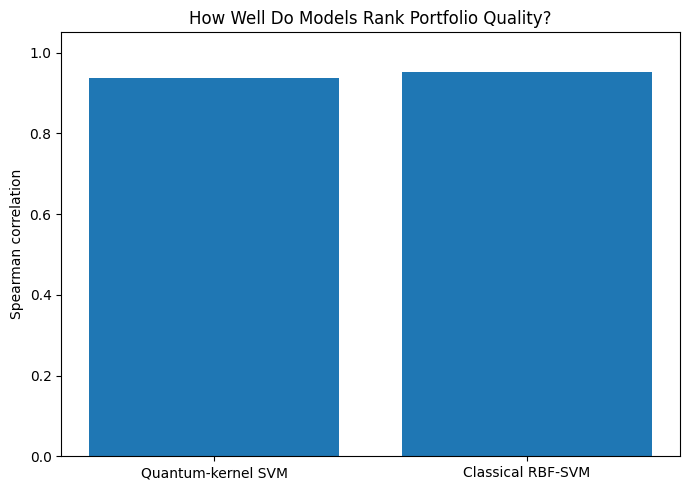

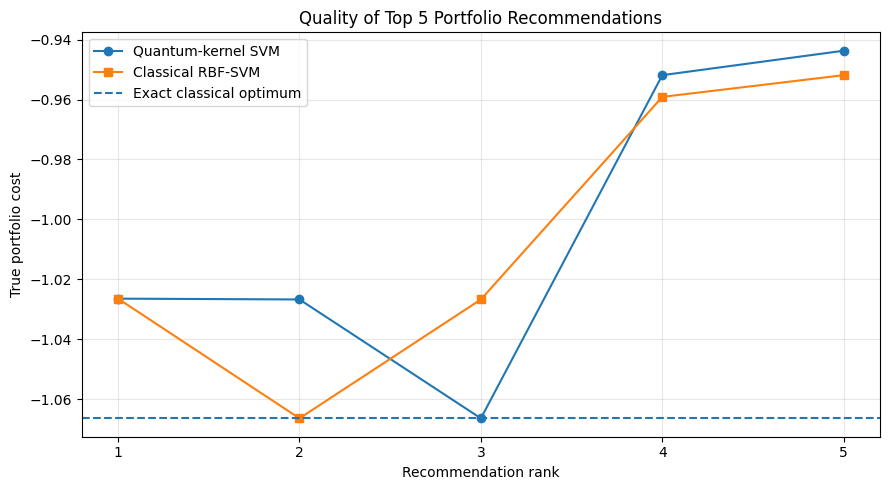

In [ ]:
# Intermediate QML — Step 8
# Visual comparison of quantum and classical recommendations

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Rank portfolios using the tuned quantum model and classical model
quantum_order = np.argsort(tuned_quantum_scores)[::-1]
classical_order = np.argsort(classical_scores)[::-1]

quantum_top_indices = candidate_indices[quantum_order[:5]]
classical_top_indices = candidate_indices[classical_order[:5]]

# Print a comparison table
summary = pd.DataFrame({
    "Metric": [
        "Test accuracy",
        "Balanced test accuracy",
        "Optimum rank (lower is better)",
        "Top-1 cost gap (lower is better)",
        "Best cost in top 5 (lower is better)",
        "Spearman correlation (higher is better)"
    ],
    "Quantum SVM": [
        test_accuracy,
        test_balanced_accuracy,
        quantum_ranking_results["optimum_rank"],
        quantum_ranking_results["top1_cost_gap"],
        quantum_ranking_results["top5_best_cost"],
        quantum_ranking_results["spearman"]
    ],
    "Classical SVM": [
        classical_accuracy,
        classical_balanced_accuracy,
        classical_ranking_results["optimum_rank"],
        classical_ranking_results["top1_cost_gap"],
        classical_ranking_results["top5_best_cost"],
        classical_ranking_results["spearman"]
    ]
})

print("FINAL MODEL COMPARISON")
display(summary)


# Plot 1: Ranking correlation
plt.figure(figsize=(7, 5))

plt.bar(
    ["Quantum-kernel SVM", "Classical RBF-SVM"],
    [
        quantum_ranking_results["spearman"],
        classical_ranking_results["spearman"]
    ]
)

plt.ylabel("Spearman correlation")
plt.title("How Well Do Models Rank Portfolio Quality?")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


# Plot 2: True costs of the top 5 recommendations
# More negative cost means a better portfolio.

quantum_costs_top5 = portfolio_costs[quantum_top_indices]
classical_costs_top5 = portfolio_costs[classical_top_indices]

ranks = np.arange(1, 6)

plt.figure(figsize=(9, 5))

plt.plot(
    ranks,
    quantum_costs_top5,
    marker="o",
    label="Quantum-kernel SVM"
)

plt.plot(
    ranks,
    classical_costs_top5,
    marker="s",
    label="Classical RBF-SVM"
)

plt.axhline(
    best_cost,
    linestyle="--",
    label="Exact classical optimum"
)

plt.xlabel("Recommendation rank")
plt.ylabel("True portfolio cost")
plt.title("Quality of Top 5 Portfolio Recommendations")
plt.xticks(ranks)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Quantum SVM C: 10.0
Classical SVM parameters: {'svm__C': 1, 'svm__gamma': 'scale'}


,Model,Optimum rank,Top-1 cost,Top-1 cost gap,Best cost in top 5,Best cost in top 10,Good portfolios in top 10,Spearman correlation
0,Quantum SVM (C=10),3,-1.026446,0.039946,-1.066392,-1.066392,10,0.951988
1,Classical RBF-SVM,2,-1.026446,0.039946,-1.066392,-1.066392,10,0.951296


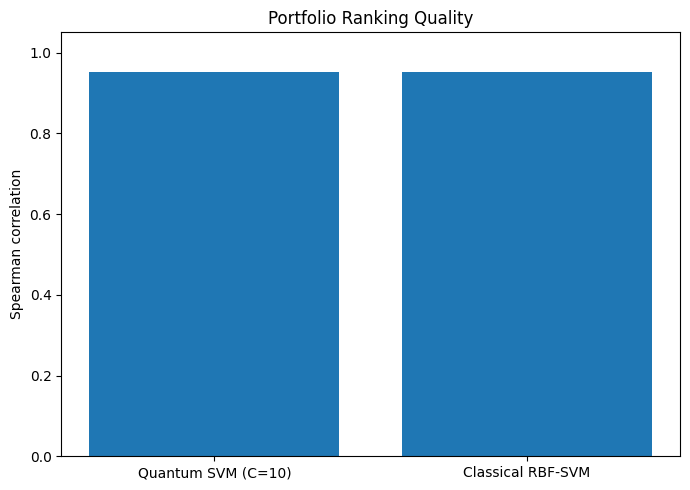

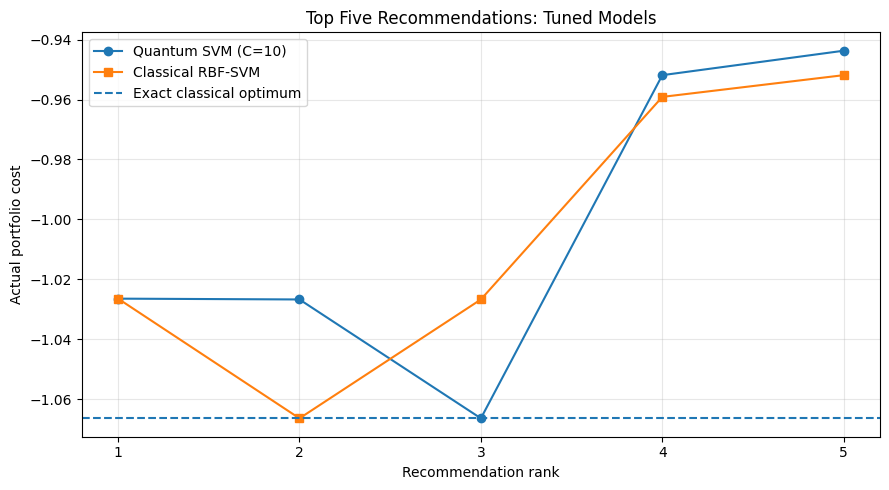

In [ ]:
# Final comparison using tuned quantum SVM (C=10)
# and tuned classical RBF-SVM

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

print(f"Quantum SVM C: {best_quantum_C}")
print(
    "Classical SVM parameters:",
    classical_rank_search.best_params_
)

def evaluate_ranking(scores, model_name):
    order = np.argsort(scores)[::-1]
    ranked_indices = candidate_indices[order]

    top1 = int(ranked_indices[0])
    top5 = ranked_indices[:5]
    top10 = ranked_indices[:10]

    optimum_rank = (
        np.where(ranked_indices == best_index)[0][0] + 1
    )

    return {
        "Model": model_name,
        "Optimum rank": int(optimum_rank),
        "Top-1 cost": float(portfolio_costs[top1]),
        "Top-1 cost gap": float(
            portfolio_costs[top1] - best_cost
        ),
        "Best cost in top 5": float(
            portfolio_costs[top5].min()
        ),
        "Best cost in top 10": float(
            portfolio_costs[top10].min()
        ),
        "Good portfolios in top 10": int(
            np.sum(
                portfolio_costs[top10]
                <= ranking_good_threshold
            )
        ),
        "Spearman correlation": float(
            spearmanr(
                scores,
                -portfolio_costs[candidate_indices]
            ).statistic
        ),
        "Ranking indices": ranked_indices
    }


quantum_final = evaluate_ranking(
    tuned_quantum_scores,
    "Quantum SVM (C=10)"
)

classical_final = evaluate_ranking(
    classical_scores,
    "Classical RBF-SVM"
)

# Display metrics without the internal ranking arrays
metrics_to_show = [
    "Model",
    "Optimum rank",
    "Top-1 cost",
    "Top-1 cost gap",
    "Best cost in top 5",
    "Best cost in top 10",
    "Good portfolios in top 10",
    "Spearman correlation"
]

final_table = pd.DataFrame([
    {k: v for k, v in result.items()
     if k in metrics_to_show}
    for result in [quantum_final, classical_final]
])

display(final_table)


# Plot 1: Ranking correlation
plt.figure(figsize=(7, 5))

plt.bar(
    ["Quantum SVM (C=10)", "Classical RBF-SVM"],
    [
        quantum_final["Spearman correlation"],
        classical_final["Spearman correlation"]
    ]
)

plt.ylabel("Spearman correlation")
plt.title("Portfolio Ranking Quality")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


# Plot 2: True costs of the top five portfolios
# Lower (more negative) cost is better.

plt.figure(figsize=(9, 5))

for result, marker in [
    (quantum_final, "o"),
    (classical_final, "s")
]:
    ranked = result["Ranking indices"][:5]
    costs = portfolio_costs[ranked]

    plt.plot(
        np.arange(1, 6),
        costs,
        marker=marker,
        label=result["Model"]
    )

plt.axhline(
    best_cost,
    linestyle="--",
    label="Exact classical optimum"
)

plt.xlabel("Recommendation rank")
plt.ylabel("Actual portfolio cost")
plt.title("Top Five Recommendations: Tuned Models")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Intermediate Level: Quantum Machine Learning for Portfolio Optimization

### 1. Objective

The objective is to investigate whether a quantum machine learning model can learn to identify promising portfolios and rank candidate solutions for a 12-stock portfolio optimization problem, selecting exactly six stocks.

### 2. Dataset and classical reference

We generated a reproducible synthetic dataset containing 12 stocks, expected returns, and a positive-semidefinite covariance matrix. All 924 valid portfolios were enumerated.

The portfolio objective was:

\[
C(x)=q x^\top\Sigma x-\mu^\top x+
\lambda\left(\sum_i x_i-K\right)^2
\]

where \(q=0.5\), \(\lambda=1.0\), and \(K=6\).

The exact classical optimum selected Stocks 2, 6, 7, 9, 11, and 12, with a minimum cost of **−1.066392**.

### 3. Quantum machine learning methodology

We implemented a 12-qubit variational quantum feature map with two repetitions. Each valid portfolio was encoded into a quantum state, and squared state overlaps were used to construct a quantum fidelity kernel.

A Support Vector Machine (SVM) trained using the precomputed quantum kernel classified portfolios as good or poor. We labeled the lowest-cost quartile as good and the highest-cost quartile as poor, using thresholds calculated from the training pool only. Intermediate-cost portfolios were excluded from classifier training.

We trained a classical RBF-kernel SVM on the same ranking-training examples as a baseline. Its hyperparameters were selected through five-fold cross-validation. The quantum SVM was similarly tuned, selecting \(C=10\).

### 4. Classification results

On the original held-out classification set of 120 labeled portfolios, both initial SVM models achieved 100% accuracy and 100% balanced accuracy.

During quantum SVM hyperparameter tuning, five-fold cross-validation also achieved 100% balanced accuracy at \(C=10\) and \(C=100\).

These results concern the selected good and poor classes only; they do not establish perfect performance across every possible portfolio.

### 5. Portfolio ranking results

For the ranking experiment, the exact optimum was excluded from model training and included among the held-out candidates. The models ranked 231 candidates using their decision scores.

| Metric | Quantum SVM (C=10) | Classical RBF-SVM |
|---|---:|---:|
| Rank of exact optimum | 3 | 2 |
| Top-1 portfolio cost | −1.026446 | −1.026446 |
| Top-1 cost gap | 0.039946 | 0.039946 |
| Best cost among top 5 | −1.066392 | −1.066392 |
| Best cost among top 10 | −1.066392 | −1.066392 |
| Good portfolios among top 10 | 10 | 10 |
| Spearman correlation | 0.951988 | 0.951296 |

Both models included the exact classical optimum among their top five recommendations. The classical model ranked it second, while the quantum model ranked it third.

### 6. Conclusions and limitations

The experiment demonstrates a working hybrid quantum machine learning pipeline using quantum state encoding, fidelity kernels, and classical SVM classification and ranking.

Both approaches performed well on this synthetic problem. The classical model was better at placing the exact optimum near the top of its ranking, while the quantum model achieved a marginally higher Spearman correlation. The difference in correlation is small, and one experimental split is insufficient to establish that either approach is statistically superior.

The experiment does not demonstrate quantum advantage. Exhaustive enumeration is feasible for 924 portfolios, and the classical methods perform comparably. Future work could assess ranking stability across multiple data splits and seeds, explore alternative feature maps, and compare computational cost more rigorously.

Encoding all valid portfolios into quantum states...
State matrix shape: (924, 4096)

Computing the complete quantum fidelity kernel...
Full quantum kernel validated: (924, 924)

STABILITY EXPERIMENT — SEED 2027
Labeled training examples: 346
Held-out candidates: 232
Quantum: C=10.0, optimum rank=2, Spearman=0.9503
Classical: params={'C': 10.0, 'gamma': 'scale'}, optimum rank=1, Spearman=0.9598

STABILITY EXPERIMENT — SEED 2028
Labeled training examples: 346
Held-out candidates: 232
Quantum: C=10.0, optimum rank=1, Spearman=0.9474
Classical: params={'C': 1.0, 'gamma': 'scale'}, optimum rank=1, Spearman=0.9525

STABILITY EXPERIMENT — SEED 2029
Labeled training examples: 346
Held-out candidates: 232
Quantum: C=1.0, optimum rank=1, Spearman=0.9457
Classical: params={'C': 1.0, 'gamma': 'scale'}, optimum rank=1, Spearman=0.9574

STABILITY EXPERIMENT — SEED 2030
Labeled training examples: 346
Held-out candidates: 232
Quantum: C=1.0, optimum rank=2, Spearman=0.9393
Classical: params={'C': 1.0

,seed,train_examples,candidate_count,quantum_C,quantum_CV_balanced_accuracy,quantum_optimum_rank,quantum_top1_gap,quantum_top5_gap,quantum_top10_gap,quantum_spearman,classical_C,classical_gamma,classical_CV_balanced_accuracy,classical_optimum_rank,classical_top1_gap,classical_top5_gap,classical_top10_gap,classical_spearman
0,2027,346,232,10.0,1.0,2,0.0397,0.0,0.0,0.9503,10.0,scale,1.0,1,0.0,0.0,0.0,0.9598
1,2028,346,232,10.0,1.0,1,0.0000,0.0,0.0,0.9474,1.0,scale,1.0,1,0.0,0.0,0.0,0.9525
2,2029,346,232,1.0,1.0,1,0.0000,0.0,0.0,0.9457,1.0,scale,1.0,1,0.0,0.0,0.0,0.9574
3,2030,346,232,1.0,1.0,2,0.0549,0.0,0.0,0.9393,1.0,scale,1.0,1,0.0,0.0,0.0,0.9510
4,2031,346,232,1.0,1.0,1,0.0000,0.0,0.0,0.9516,1.0,scale,1.0,1,0.0,0.0,0.0,0.9607



MEAN AND STANDARD DEVIATION ACROSS SEEDS
----------------------------------------------------------------------


,Metric,Quantum mean,Quantum std,Classical mean,Classical std
0,optimum_rank,1.40000,0.54772,1.00000,0.00000
1,top1_gap,0.01891,0.02644,0.00000,0.00000
2,top5_gap,0.00000,0.00000,0.00000,0.00000
3,spearman,0.94687,0.00484,0.95627,0.00434


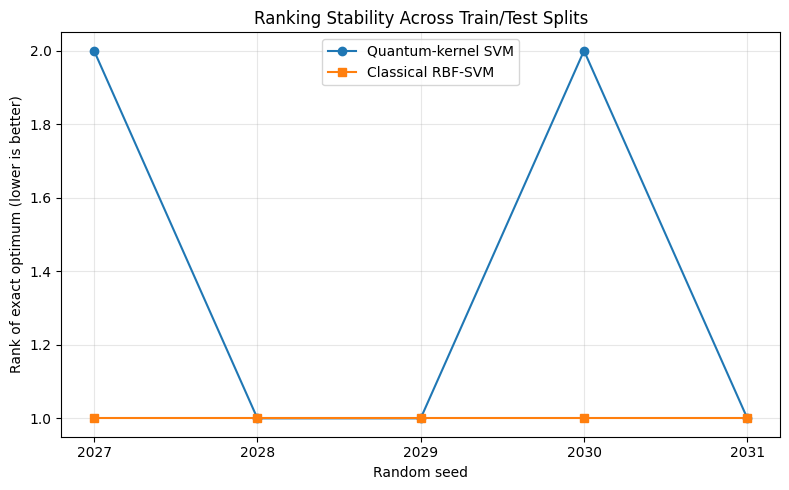

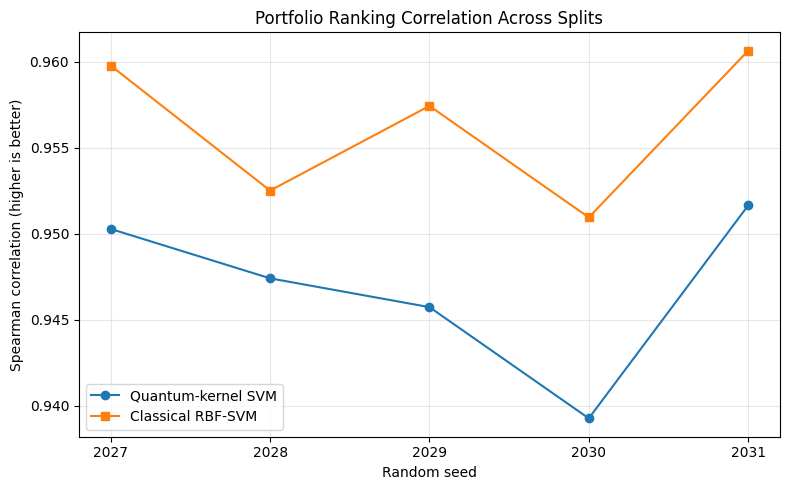

In [ ]:
# Intermediate QML — Step 10
# Stability across five independent train/test splits

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score

# --------------------------------------------------
# 1. Precompute the quantum states and kernel once
# --------------------------------------------------

print("Encoding all valid portfolios into quantum states...")

all_states = np.stack([
    quantum_feature_state(x)
    for x in X
])

print("State matrix shape:", all_states.shape)

print("\nComputing the complete quantum fidelity kernel...")

K_all = np.abs(
    all_states.conj() @ all_states.T
) ** 2

K_all = np.clip(K_all.real, 0.0, 1.0)

assert K_all.shape == (924, 924)
assert np.allclose(K_all, K_all.T, atol=1e-8)
assert np.allclose(np.diag(K_all), 1.0, atol=1e-8)

# The feature vectors are no longer needed.
del all_states

print("Full quantum kernel validated:", K_all.shape)


# --------------------------------------------------
# 2. Experiment configuration
# --------------------------------------------------

seeds = [2027, 2028, 2029, 2030, 2031]

quantum_C_values = [0.1, 1.0, 10.0, 100.0]
classical_C_values = [0.1, 1.0, 10.0, 100.0]
classical_gamma_values = ["scale", 0.01, 0.1, 1.0]

records = []
all_portfolio_indices = np.arange(len(X))

# Keep the optimum out of training in every experiment.
non_optimal_indices = all_portfolio_indices[
    all_portfolio_indices != best_index
]


# --------------------------------------------------
# 3. Helper functions
# --------------------------------------------------

def rank_metrics(scores, candidate_ids):
    order = np.argsort(scores)[::-1]
    ranked_ids = candidate_ids[order]

    optimum_rank = (
        np.flatnonzero(ranked_ids == best_index)[0] + 1
    )

    top1_id = int(ranked_ids[0])
    top5_ids = ranked_ids[:5]
    top10_ids = ranked_ids[:10]

    return {
        "optimum_rank": int(optimum_rank),
        "top1_gap": float(
            portfolio_costs[top1_id] - best_cost
        ),
        "top5_gap": float(
            portfolio_costs[top5_ids].min() - best_cost
        ),
        "top10_gap": float(
            portfolio_costs[top10_ids].min() - best_cost
        ),
        "spearman": float(
            spearmanr(
                scores,
                -portfolio_costs[candidate_ids]
            ).statistic
        )
    }


def tune_quantum_svm(K_train, y_train, cv):
    """Tune C using training-only cross-validation."""

    cv_scores = []

    for C_value in quantum_C_values:
        fold_scores = []

        for tr, val in cv.split(
            np.zeros(len(y_train)), y_train
        ):
            model = SVC(
                kernel="precomputed",
                C=C_value,
                class_weight="balanced"
            )

            model.fit(
                K_train[np.ix_(tr, tr)],
                y_train[tr]
            )

            predictions = model.predict(
                K_train[np.ix_(val, tr)]
            )

            fold_scores.append(
                balanced_accuracy_score(
                    y_train[val], predictions
                )
            )

        cv_scores.append(np.mean(fold_scores))

    best_position = int(np.argmax(cv_scores))

    return (
        quantum_C_values[best_position],
        float(cv_scores[best_position])
    )


def tune_classical_svm(X_train, y_train, cv):
    """Tune C and gamma using training-only cross-validation."""

    best_params = None
    best_cv_score = -np.inf

    for C_value in classical_C_values:
        for gamma_value in classical_gamma_values:
            fold_scores = []

            for tr, val in cv.split(
                X_train, y_train
            ):
                model = Pipeline([
                    ("scaler", StandardScaler()),
                    ("svm", SVC(
                        kernel="rbf",
                        C=C_value,
                        gamma=gamma_value,
                        class_weight="balanced"
                    ))
                ])

                model.fit(
                    X_train[tr], y_train[tr]
                )

                predictions = model.predict(
                    X_train[val]
                )

                fold_scores.append(
                    balanced_accuracy_score(
                        y_train[val], predictions
                    )
                )

            mean_score = float(np.mean(fold_scores))

            if mean_score > best_cv_score:
                best_cv_score = mean_score
                best_params = {
                    "C": C_value,
                    "gamma": gamma_value
                }

    return best_params, best_cv_score


# --------------------------------------------------
# 4. Run the five experiments
# --------------------------------------------------

for seed in seeds:
    print("\n" + "=" * 55)
    print(f"STABILITY EXPERIMENT — SEED {seed}")
    print("=" * 55)

    # Split only the non-optimal candidates.
    # The exact optimum is added to the held-out set later.
    permutation_rng = np.random.default_rng(seed)

    shuffled = permutation_rng.permutation(
        non_optimal_indices
    )

    split_point = int(0.75 * len(shuffled))

    train_pool = shuffled[:split_point]
    test_pool = shuffled[split_point:]

    candidate_ids = np.sort(
        np.append(test_pool, best_index)
    )

    assert best_index not in train_pool
    assert len(np.intersect1d(
        train_pool, candidate_ids
    )) == 0

    # Calculate labels using the training pool only.
    train_pool_costs = portfolio_costs[train_pool]

    good_threshold_seed = np.quantile(
        train_pool_costs, 0.25
    )

    poor_threshold_seed = np.quantile(
        train_pool_costs, 0.75
    )

    labeled_mask = (
        (train_pool_costs <= good_threshold_seed)
        | (train_pool_costs >= poor_threshold_seed)
    )

    train_ids = train_pool[labeled_mask]

    X_train_seed = X[train_ids]

    y_train_seed = (
        portfolio_costs[train_ids]
        <= good_threshold_seed
    ).astype(int)

    assert set(np.unique(y_train_seed)) == {0, 1}

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    print("Labeled training examples:", len(train_ids))
    print("Held-out candidates:", len(candidate_ids))

    # ----------------------------------------------
    # Quantum model
    # ----------------------------------------------

    K_train_seed = K_all[
        np.ix_(train_ids, train_ids)
    ]

    K_candidate_seed = K_all[
        np.ix_(candidate_ids, train_ids)
    ]

    q_C, q_cv_score = tune_quantum_svm(
        K_train_seed, y_train_seed, cv
    )

    q_model = SVC(
        kernel="precomputed",
        C=q_C,
        class_weight="balanced"
    )

    q_model.fit(K_train_seed, y_train_seed)

    q_scores = q_model.decision_function(
        K_candidate_seed
    )

    q_metrics = rank_metrics(
        q_scores, candidate_ids
    )

    # ----------------------------------------------
    # Classical model
    # ----------------------------------------------

    c_params, c_cv_score = tune_classical_svm(
        X_train_seed, y_train_seed, cv
    )

    c_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=c_params["C"],
            gamma=c_params["gamma"],
            class_weight="balanced"
        ))
    ])

    c_model.fit(X_train_seed, y_train_seed)

    c_scores = c_model.decision_function(
        X[candidate_ids]
    )

    c_metrics = rank_metrics(
        c_scores, candidate_ids
    )

    # Save results from both methods.
    records.append({
        "seed": seed,
        "train_examples": len(train_ids),
        "candidate_count": len(candidate_ids),

        "quantum_C": q_C,
        "quantum_CV_balanced_accuracy": q_cv_score,
        "quantum_optimum_rank": q_metrics["optimum_rank"],
        "quantum_top1_gap": q_metrics["top1_gap"],
        "quantum_top5_gap": q_metrics["top5_gap"],
        "quantum_top10_gap": q_metrics["top10_gap"],
        "quantum_spearman": q_metrics["spearman"],

        "classical_C": c_params["C"],
        "classical_gamma": str(c_params["gamma"]),
        "classical_CV_balanced_accuracy": c_cv_score,
        "classical_optimum_rank": c_metrics["optimum_rank"],
        "classical_top1_gap": c_metrics["top1_gap"],
        "classical_top5_gap": c_metrics["top5_gap"],
        "classical_top10_gap": c_metrics["top10_gap"],
        "classical_spearman": c_metrics["spearman"]
    })

    print(
        f"Quantum: C={q_C}, "
        f"optimum rank={q_metrics['optimum_rank']}, "
        f"Spearman={q_metrics['spearman']:.4f}"
    )

    print(
        f"Classical: params={c_params}, "
        f"optimum rank={c_metrics['optimum_rank']}, "
        f"Spearman={c_metrics['spearman']:.4f}"
    )


# --------------------------------------------------
# 5. Summarize stability across random seeds
# --------------------------------------------------

results_df = pd.DataFrame(records)

print("\n" + "=" * 70)
print("STABILITY RESULTS — EVERY RANDOM SEED")
print("=" * 70)

display(results_df.round(4))

metric_pairs = [
    (
        "optimum_rank",
        "quantum_optimum_rank",
        "classical_optimum_rank"
    ),
    (
        "top1_gap",
        "quantum_top1_gap",
        "classical_top1_gap"
    ),
    (
        "top5_gap",
        "quantum_top5_gap",
        "classical_top5_gap"
    ),
    (
        "spearman",
        "quantum_spearman",
        "classical_spearman"
    )
]

print("\nMEAN AND STANDARD DEVIATION ACROSS SEEDS")
print("-" * 70)

summary_rows = []

for metric, quantum_col, classical_col in metric_pairs:
    summary_rows.append({
        "Metric": metric,
        "Quantum mean": results_df[quantum_col].mean(),
        "Quantum std": results_df[quantum_col].std(ddof=1),
        "Classical mean": results_df[classical_col].mean(),
        "Classical std": results_df[classical_col].std(ddof=1)
    })

summary_df = pd.DataFrame(summary_rows)

display(summary_df.round(5))


# --------------------------------------------------
# 6. Visualization
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["seed"],
    results_df["quantum_optimum_rank"],
    marker="o",
    label="Quantum-kernel SVM"
)

plt.plot(
    results_df["seed"],
    results_df["classical_optimum_rank"],
    marker="s",
    label="Classical RBF-SVM"
)

plt.xlabel("Random seed")
plt.ylabel("Rank of exact optimum (lower is better)")
plt.title("Ranking Stability Across Train/Test Splits")
plt.xticks(seeds)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    results_df["seed"],
    results_df["quantum_spearman"],
    marker="o",
    label="Quantum-kernel SVM"
)

plt.plot(
    results_df["seed"],
    results_df["classical_spearman"],
    marker="s",
    label="Classical RBF-SVM"
)

plt.xlabel("Random seed")
plt.ylabel("Spearman correlation (higher is better)")
plt.title("Portfolio Ranking Correlation Across Splits")
plt.xticks(seeds)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Ranking Stability Across Random Splits

### Experimental setup

We evaluated the quantum-kernel SVM and classical RBF-SVM across five reproducible train/test splits, using seeds 2027–2031. For each split, model hyperparameters were selected through five-fold cross-validation on the training data only.

The exact classical optimum was excluded from model training and included among the held-out candidates. We measured the optimum's rank, top-five cost gap, and Spearman rank correlation between model scores and true portfolio quality.

### Results

| Metric | Quantum SVM | Classical RBF-SVM |
|---|---:|---:|
| Mean optimum rank | 1.40 | 1.00 |
| Standard deviation of optimum rank | 0.55 | 0.00 |
| Mean top-1 cost gap | 0.01891 | 0.00000 |
| Mean top-5 cost gap | 0.00000 | 0.00000 |
| Mean Spearman correlation | 0.94687 | 0.95627 |
| Standard deviation of Spearman correlation | 0.00484 | 0.00434 |

The quantum SVM ranked the exact optimum first in three of five experiments and second in two. The classical RBF-SVM ranked the exact optimum first in all five experiments.

Both models included the exact optimum among their top five recommendations for every split.

### Interpretation

The quantum-kernel SVM consistently identified high-quality portfolios and placed the exact optimum near the top of its ranking. However, the classical RBF-SVM performed better on the mean optimum rank and mean Spearman correlation in this experiment.

The difference in average ranking correlation was small, but the classical model was more consistent at ranking the exact optimum first. These findings do not establish quantum advantage.

The experiments used different splits of the same synthetic dataset. Further evaluation on independently generated datasets would be necessary to assess generalization beyond this problem instance.

In [ ]:
from qiskit import QuantumCircuit, transpile

# A small feature-map-style circuit
qc_qml_hardware = QuantumCircuit(2, 2)

# Encode two sample features as phase rotations
qc_qml_hardware.h([0, 1])
qc_qml_hardware.rz(0.8, 0)
qc_qml_hardware.rz(1.2, 1)

# Encode an interaction between the two qubits
qc_qml_hardware.cx(0, 1)
qc_qml_hardware.rz(0.4, 1)
qc_qml_hardware.cx(0, 1)

# Measure both qubits
qc_qml_hardware.measure([0, 1], [0, 1])

print(qc_qml_hardware.draw())
print("Qubits:", qc_qml_hardware.num_qubits)
print("Parameters:", qc_qml_hardware.num_parameters)

     ┌───┐┌─────────┐                     ┌─┐   
q_0: ┤ H ├┤ Rz(0.8) ├──■───────────────■──┤M├───
     ├───┤├─────────┤┌─┴─┐┌─────────┐┌─┴─┐└╥┘┌─┐
q_1: ┤ H ├┤ Rz(1.2) ├┤ X ├┤ Rz(0.4) ├┤ X ├─╫─┤M├
     └───┘└─────────┘└───┘└─────────┘└───┘ ║ └╥┘
c: 2/══════════════════════════════════════╩══╩═
                                           0  1 
Qubits: 2
Parameters: 0


In [ ]:
%pip install -q qiskit-ibm-runtime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 19.4 MB/s eta 0:00:00


## IBM Quantum Hardware Execution: Feature-Map Demonstration

Before concluding the quantum machine-learning experiments, we execute a small feature-map-style quantum circuit on a real IBM quantum processor.

The circuit uses **two qubits** and applies Hadamard gates, parameterized \(R_Z\) rotations, and CNOT gates before measurement. These operations create quantum states whose measurement distributions depend on the circuit's structure and parameters.

The circuit is transpiled for the selected IBM Quantum backend and submitted using IBM Quantum Runtime. The returned measurement counts are then analyzed to observe the outcomes produced by real quantum hardware.

**Important distinction:** This is a small hardware demonstration inspired by the quantum feature-map workflow. It is not the complete 12-qubit fidelity-kernel computation, nor does it train or evaluate the entire quantum-kernel SVM on hardware. The full QML evaluation described earlier uses the notebook's feature-map and kernel-computation workflow.

The purpose of this experiment is to demonstrate real-device execution and inspect measured outcomes, while keeping the larger machine-learning evaluation computationally manageable.

Hardware measurements can differ from ideal simulator results because of gate errors, device noise, and measurement imperfections. This experiment demonstrates quantum circuit execution, not quantum advantage.

In [ ]:
from qiskit import transpile

# Reconnect if this notebook's runtime was reset
from google.colab import userdata
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=userdata.get("IBM_QUANTUM_API_KEY"),
)

backend = service.backend("ibm_kingston")

# Compile the circuit for this real backend
qml_isa = transpile(
    qc_qml_hardware,
    backend=backend,
    optimization_level=1,
)

print("Backend:", backend.name)
print("Operational:", backend.status().operational)
print("Compiled qubits:", qml_isa.num_qubits)
print("Remaining parameters:", qml_isa.num_parameters)
print("Compiled depth:", qml_isa.depth())

qiskit_runtime_service._discover_account:WARNING:2026-10-14 12:12:03,684: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-14 12:12:07,628: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-14 12:12:07,629: Using instance: open-instance, plan: open


Backend: ibm_kingston
Operational: True
Compiled qubits: 156
Remaining parameters: 0
Compiled depth: 16


## Results, Hardware Demonstration, and Limitations

### Quantum-kernel classification

The initial evaluated split recorded 100% accuracy for both the quantum-kernel SVM and the classical RBF SVM. Because the labels are derived from a synthetic dataset with intermediate-cost examples excluded, this result should not be interpreted as proof that quantum machine learning outperforms classical learning.

### Repeated portfolio-ranking evaluation

Across five recorded evaluation splits, the quantum approach achieved an average rank of 1.4 for the exact optimum, with a mean Spearman rank correlation of approximately 0.94687. The classical comparison ranked the exact optimum first in all five recorded splits and achieved a mean Spearman correlation of approximately 0.95627.

These measurements do not show a ranking advantage for the quantum method in this experiment. They provide a comparison of how both approaches behaved on the particular synthetic instance and evaluation procedure.

### IBM Quantum hardware demonstration

The hardware experiment executed a separate two-qubit feature-map-style circuit on IBM `ibm_kingston`, using 512 measurement shots.

- Job ID: `db7n3e0r1c5c738ktlbg`.
- Measurement counts: `00 = 47`, `01 = 164`, `10 = 76`, and `11 = 225`.

This was a small circuit demonstration, not a hardware execution of the complete 12-qubit fidelity-kernel SVM training pipeline. The measured counts demonstrate that the circuit ran on quantum hardware; they do not establish that the complete machine-learning model was trained or evaluated on the device.

### Conclusion

The notebook demonstrates an end-to-end quantum-kernel learning workflow, including candidate-portfolio generation, labeled dataset preparation, quantum feature-map validation, SVM classification, and portfolio-ranking comparison.

The results illustrate how quantum-kernel methods can be experimentally compared with classical machine learning. The synthetic dataset, selected classification labels, ranking metrics, and separate hardware demonstration must all be considered when interpreting the findings. No quantum advantage is established.

In [ ]:
from qiskit_ibm_runtime import SamplerV2

# Submit the compiled circuit to real IBM hardware
sampler = SamplerV2(mode=backend)
job_qml = sampler.run([qml_isa], shots=512)

qml_hardware_job_id = job_qml.job_id()
print("Hardware job ID:", qml_hardware_job_id)
print("Backend:", backend.name)

# Retrieve measurements
qml_result = job_qml.result()
qml_counts = qml_result[0].data.c.get_counts()

print("\nHardware measurement counts:")
print(qml_counts)
print("Total shots:", sum(qml_counts.values()))

/tmp/ipykernel_1056/336083460.py:4: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Hardware job ID: db7n3e0r1c5c738ktlbg
Backend: ibm_kingston

Hardware measurement counts:
{'01': 164, '10': 76, '11': 225, '00': 47}
Total shots: 512


### Real Quantum Hardware Demonstration — Intermediate QML

**Platform:** IBM Quantum  
**Backend:** `ibm_kingston`  
**Hardware job ID:** `db7n3e0r1c5c738ktlbg`  
**Circuit:** Two-qubit feature-map-style circuit  
**Measurement shots:** 512

**Observed counts:**
- `00`: 47 (9.18%)
- `01`: 164 (32.03%)
- `10`: 76 (14.84%)
- `11`: 225 (43.95%)

**Interpretation:** The two-qubit feature-map-style circuit was successfully executed on real IBM quantum hardware. The observed distribution records the outcomes of the prepared circuit after hardware noise and measurement.

**Limitations:** This was a small hardware demonstration, not a hardware execution of the full 12-qubit quantum fidelity kernel or the quantum-kernel SVM training workflow. These counts do not establish quantum advantage or demonstrate that a quantum SVM outperforms a classical SVM.